# FGE vs SWA: cheap ensembling from a single training run (sweeps `muibmei1` / `vz9g0q7c`)

Compares the two alternatives to full curve-fitting (ALC/DE, see `analyse_qwen_rank_compare.ipynb`)
for getting an ensemble out of one training run:

- **FGE** (`muibmei1`, "FGE OpenFlat No Seg round2"): cyclical-LR snapshot ensembling. 60 finished
  runs = 4 datasets x 3 `cycle_steps` (118/222/400) x 5 seeds. Framed here by the resulting
  ensemble size (`fge_num_snapshots`: 17/9/5 respectively) rather than by `cycle_steps` directly,
  since member count is what's actually comparable to SWA/ALC.
- **SWA** (`vz9g0q7c`, "SWA OpenFlat No Seg round2"): weight-space averaging. 20 finished runs =
  4 datasets x 5 seeds. Two variants per run: `SWA(welford)` (running-mean over the tail window,
  `swa_test_*`) and `SWA(best)` (single best-validation checkpoint, no averaging, `swa_best_test_*`)
  -- both are reported, `SWA(best)` mainly as an evaluation reference point (round1 showed it can
  beat both averaging strategies).

Both sweeps share the same base config as `analyse_qwen_rank_compare.ipynb`'s `df_clean_base`:
LoRA rank=8, rho=0.25, `A(t)eB(t)` mode, single fixed point (`num_curve_segment=0`, `SegDeg=1`,
`Pretraining=True`), confirmed via `run.config['model_params']` on both sweeps. Datasets covered:
`ARC-Easy`, `ARC-Challenge`, `winogrande_m`, `winogrande_s` (no `obqa`/`boolq` in either sweep).

Also brings in two reference points from the same base-rank sweeps (`we8wq8n7`/`kru2lo9d`) used in
`analyse_qwen_rank_compare.ipynb`:

- **MAP**: each individually-pretrained control point's own test performance, no curve/ensembling
  at all (`cp_fixed_{i}_test_*` summary keys, logged for every finished `Pretraining=True` run --
  see `analyse_qwen_only_new DS.ipynb`'s `BmaMode="MAP"` handling for the original pattern this is
  based on). This is the "just fine-tune once" floor.
- **ALC(5,2)**: the 5-control-point (`N=5`, `M=2`) Bezier curve's uniform-BMA result
  (`test_ppd_uniform_*`), i.e. the expensive multi-point-curve-fit ceiling FGE/SWA are trying to
  approximate cheaply from a single training run.

Metrics: `fge_acc/ece/brier/ll` are the ensembled-snapshot test-split result
(`post_pred_performance(..., key_prefix="fge_")` on `data.get("test")` in `qwen_fge.py`).
`swa_test_*`/`swa_best_test_*` are both test-split, from `qwen_swa.py`.

### init

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["JAX_PLATFORMS"] = "cpu"

import wandb
from tqdm import tqdm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%load_ext autoreload
%autoreload 2

In [2]:
def get_figsize(columnwidth, wf=0.5, hf=(5.**0.5-1.0)/2.0, ):
    """Parameters:
    - wf [float]:  width fraction in columnwidth units
    - hf [float]:  height fraction in columnwidth units.
                    Set by default to golden ratio.
    - columnwidth [float]: width of the column in latex. Get this from LaTeX
                            using \\showthe\\columnwidth
    Returns:  [fig_width,fig_height]: that should be given to matplotlib
    """
    fig_width_pt = columnwidth*wf
    inches_per_pt = 1.0/72.27               # Convert pt to inch
    fig_width = fig_width_pt*inches_per_pt  # width in inches
    fig_height = fig_width*hf      # height in inches
    return [fig_width, fig_height]


fig_width_pt = 397.48499  # Get this from LaTeX using \showthe\columnwidth
inches_per_pt = 1.0/72.27               # Convert pt to inches
golden_mean = (np.sqrt(5)-1.0)/2.0         # Aesthetic ratio
fig_width = fig_width_pt*inches_per_pt  # width in inches
fig_height = fig_width*golden_mean       # height in inches
figsize = [fig_width, fig_height]
print("Figure size=", figsize)
tex_fonts = {
    "text.usetex": True,
    "font.family": "Nimbus Sans",
    "axes.labelsize": 10,
    "font.size": 10,
    "legend.fontsize": 9,
    "legend.title_fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize": figsize
}
plt.rcParams.update(tex_fonts)

Figure size= [5.499999861629998, 3.399186852607058]


### Load sweep results

`collect_fge_results` pulls `fge_acc/ece/brier/ll` (test-split, ensembled over FGE snapshots) plus
the `cycle_steps`/`num_snapshots` config. `collect_swa_results` pulls both SWA variants -- Welford
running mean (`swa_test_*`) and best-checkpoint (`swa_best_test_*`) -- as separate `Model` rows.
`collect_baseline_results` pulls MAP (`cp_fixed_{i}_test_*`, one row per individually-pretrained
control point) and ALC(5,2) (`test_ppd_uniform_*`, restricted to `N=5, M=2`) from the base-rank
ALC/DE sweeps.

In [3]:
api = wandb.Api()


def _dataset_name(dataset_path):
    return "_".join(dataset_path.split("/")[-1].split(".")[0].split("_")[:-1])


def collect_fge_results(sweep_id, project="qwen_PtoC_newDS", entity="ddold"):
    results = []
    t_run = tqdm(api.sweep(f"{entity}/{project}/{sweep_id}").runs)
    t_run.set_description(sweep_id)
    for run in t_run:
        if run.state != "finished":
            continue
        t_run.set_postfix_str(run.name)
        cfg = run.config
        summary = run.summary
        results.append(dict(
            Id=run.id,
            Dataset=_dataset_name(cfg["data"]["dataset_path"]),
            Seed=cfg["rng_seed"],
            CycleSteps=cfg["fge"]["cycle_steps"],
            NumSnapshots=summary.get("fge_num_snapshots", -1),
            acc=summary.get("fge_acc", np.nan),
            ece=summary.get("fge_ece", np.nan),
            brier=summary.get("fge_brier", np.nan),
            ll=summary.get("fge_ll", np.nan),
            SweepId=sweep_id,
        ))
    return pd.DataFrame(results)


def collect_swa_results(sweep_id, project="qwen_PtoC_newDS", entity="ddold"):
    results = []
    t_run = tqdm(api.sweep(f"{entity}/{project}/{sweep_id}").runs)
    t_run.set_description(sweep_id)
    for run in t_run:
        if run.state != "finished":
            continue
        t_run.set_postfix_str(run.name)
        cfg = run.config
        summary = run.summary
        base = dict(
            Id=run.id,
            Dataset=_dataset_name(cfg["data"]["dataset_path"]),
            Seed=cfg["rng_seed"],
            SweepId=sweep_id,
        )
        for model_label, prefix in [("SWA(welford)", "swa_test_"), ("SWA(best)", "swa_best_test_")]:
            row = dict(base)
            row["Model"] = model_label
            row["acc"] = summary.get(f"{prefix}acc", np.nan)
            row["ece"] = summary.get(f"{prefix}ece", np.nan)
            row["brier"] = summary.get(f"{prefix}brier", np.nan)
            row["ll"] = summary.get(f"{prefix}ll", np.nan)
            results.append(row)
    return pd.DataFrame(results)


def collect_baseline_results(sweep_ids, project="qwen_PtoC_newDS", entity="ddold", lora_rho=0.25):
    """MAP (each individually pretrained control point, no curve) + ALC(5,2) (5-cp curve, uniform
    BMA), from the same base-rank sweeps as analyse_qwen_rank_compare.ipynb's df_clean_base."""
    results = []
    for s in set(sweep_ids):
        t_run = tqdm(api.sweep(f"{entity}/{project}/{s}").runs)
        t_run.set_description(s)
        for run in t_run:
            if run.state != "finished":
                continue
            t_run.set_postfix_str(run.name)
            cfg = run.config
            mp = cfg["model_params"]
            lora = mp["lora_params"]
            if lora.get("lora_mode") != "A(t)eB(t)" or lora.get("lora_rho") != lora_rho:
                continue
            summary = run.summary
            NCurveSegment = mp["num_curve_segment"]
            CurveDegree = mp["SegDeg"]
            N = NCurveSegment + 1
            M = CurveDegree - 1
            base = dict(
                Id=run.id,
                Dataset=_dataset_name(cfg["data"]["dataset_path"]),
                Seed=cfg["rng_seed"],
                SweepId=s,
            )

            if mp["Pretraining"]:
                for k in summary.keys():
                    if k.startswith("cp_fixed_") and k.endswith("_test_acc"):
                        i = k.split("_")[2]
                        row = dict(base)
                        row["Model"] = "MAP"
                        row["acc"] = summary.get(f"cp_fixed_{i}_test_acc", np.nan)
                        row["ece"] = summary.get(f"cp_fixed_{i}_test_ece", np.nan)
                        row["brier"] = summary.get(f"cp_fixed_{i}_test_brier", np.nan)
                        row["ll"] = summary.get(f"cp_fixed_{i}_test_ll", np.nan)
                        results.append(row)

            if N == 5 and M == 2:
                row = dict(base)
                row["Model"] = "ALC(5,2)"
                row["acc"] = summary.get("test_ppd_uniform_acc", np.nan)
                row["ece"] = summary.get("test_ppd_uniform_ece", np.nan)
                row["brier"] = summary.get("test_ppd_uniform_brier", np.nan)
                row["ll"] = summary.get("test_ppd_uniform_ll", np.nan)
                results.append(row)

    return pd.DataFrame(results)

### Load data — FGE (`muibmei1`), SWA (`vz9g0q7c`), and MAP/ALC(5,2) baselines (`we8wq8n7`,
`kru2lo9d`)

In [4]:
# round2 (winogrande_s/m, ARC-Easy/Challenge) + round3 obqa
df_fge = pd.concat([collect_fge_results(s) for s in ["muibmei1", "oeymhnlp"]], ignore_index=True)
df_swa = pd.concat([collect_swa_results(s) for s in ["vz9g0q7c", "k0h158ci"]], ignore_index=True)
df_baseline = collect_baseline_results(["we8wq8n7", "kru2lo9d"])
# restrict the baseline sweeps' extra datasets (obqa/boolq) down to what FGE/SWA actually cover
df_baseline = df_baseline[df_baseline["Dataset"].isin(df_fge["Dataset"].unique())].copy()
print(f"FGE: {len(df_fge)} rows")
print(f"SWA: {len(df_swa)} rows")
print(f"Baseline (MAP + ALC(5,2)): {len(df_baseline)} rows")
df_fge.head()

  0%|          | 0/60 [00:00<?, ?it/s]

muibmei1:   0%|          | 0/60 [00:00<?, ?it/s]

muibmei1:   0%|          | 0/60 [00:00<?, ?it/s, dazzling-sweep-60]

muibmei1:   0%|          | 0/60 [00:00<?, ?it/s, sweet-sweep-59]   

muibmei1:   0%|          | 0/60 [00:00<?, ?it/s, glad-sweep-58] 

muibmei1:   0%|          | 0/60 [00:00<?, ?it/s, jumping-sweep-57]

... (333 outputs left out)

kru2lo9d:  78%|███████▊  | 31/40 [00:00<00:00, 247.39it/s, upbeat-sweep-1]

kru2lo9d: 100%|██████████| 40/40 [00:00<00:00, 275.92it/s, upbeat-sweep-1]

FGE: 60 rows
SWA: 40 rows
Baseline (MAP + ALC(5,2)): 780 rows


,Id,Dataset,Seed,CycleSteps,NumSnapshots,acc,ece,brier,ll,SweepId
0,fa32sgw2,ARC-Easy,8000,118,17,0.963158,0.018077,0.055789,-0.117228,muibmei1
1,xfh75yap,ARC-Easy,400,118,17,0.964912,0.018783,0.053733,-0.107621,muibmei1
2,g48kh2ia,ARC-Easy,20,118,17,0.959649,0.026110,0.061699,-0.120719,muibmei1
3,eusjhfwv,ARC-Easy,2,118,17,0.968421,0.021964,0.054458,-0.113937,muibmei1
4,55ickeve,ARC-Easy,1,118,17,0.966667,0.023017,0.055018,-0.107635,muibmei1


### Sanity check: run coverage per (Dataset, NumSnapshots) / (Dataset, Model) / (Dataset, Model)

In [5]:
display(df_fge.groupby(["Dataset", "NumSnapshots"]).size().rename("n_runs"))
display(df_swa.groupby(["Dataset", "Model"]).size().rename("n_runs"))
display(df_baseline.groupby(["Dataset", "Model"]).size().rename("n_runs"))

Dataset        NumSnapshots
ARC-Challenge  5               5
               9               5
               17              5
ARC-Easy       5               5
               9               5
               17              5
winogrande_m   5               5
               9               5
               17              5
winogrande_s   5               5
               9               5
               17              5
Name: n_runs, dtype: int64

Dataset        Model       
ARC-Challenge  SWA(best)       5
               SWA(welford)    5
ARC-Easy       SWA(best)       5
               SWA(welford)    5
winogrande_m   SWA(best)       5
               SWA(welford)    5
winogrande_s   SWA(best)       5
               SWA(welford)    5
Name: n_runs, dtype: int64

Dataset        Model   
ARC-Challenge  ALC(5,2)      5
               MAP         190
ARC-Easy       ALC(5,2)      5
               MAP         190
winogrande_m   ALC(5,2)      5
               MAP         190
winogrande_s   ALC(5,2)      5
               MAP         190
Name: n_runs, dtype: int64

### Build one plotting frame

FGE rows get a `Model` label per ensemble size (`FGE(N=5|9|17)`, from `fge_num_snapshots` -- the
inverse of `cycle_steps`: fewer/longer cycles -> fewer, more spread-out snapshots); SWA rows
already carry `Model in {"SWA(welford)", "SWA(best)"}`; baseline rows carry
`Model in {"MAP", "ALC(5,2)"}`. All are melted to long form (`Dataset`, `Model`, `Metric`, `value`)
and concatenated.

In [6]:
value_cols = ["acc", "ece", "brier", "ll"]

df_fge_labeled = df_fge.assign(Model=lambda d: "FGE(N=" + d["NumSnapshots"].astype(int).astype(str) + ")")
df_plot_fge = df_fge_labeled.melt(
    id_vars=["Id", "Dataset", "Seed", "CycleSteps", "NumSnapshots", "SweepId", "Model"],
    value_vars=value_cols, var_name="Metric", value_name="value",
)

df_plot_swa = df_swa.melt(
    id_vars=["Id", "Dataset", "Seed", "SweepId", "Model"],
    value_vars=value_cols, var_name="Metric", value_name="value",
)

df_plot_baseline = df_baseline.melt(
    id_vars=["Id", "Dataset", "Seed", "SweepId", "Model"],
    value_vars=value_cols, var_name="Metric", value_name="value",
)

df_plot = pd.concat([df_plot_baseline, df_plot_fge, df_plot_swa], ignore_index=True)
print(df_plot["Model"].unique())
df_plot.head()

['MAP' 'ALC(5,2)' 'FGE(N=17)' 'FGE(N=9)' 'FGE(N=5)' 'SWA(welford)'
 'SWA(best)']


,Id,Dataset,Seed,SweepId,Model,Metric,value,CycleSteps,NumSnapshots
0,d5b1doju,ARC-Easy,8000,we8wq8n7,MAP,acc,0.963158,NaN,NaN
1,d5b1doju,ARC-Easy,8000,we8wq8n7,MAP,acc,0.959649,NaN,NaN
2,d5b1doju,ARC-Easy,8000,we8wq8n7,MAP,acc,0.966667,NaN,NaN
3,d5b1doju,ARC-Easy,8000,we8wq8n7,MAP,acc,0.964912,NaN,NaN
4,d5b1doju,ARC-Easy,8000,we8wq8n7,MAP,acc,0.966667,NaN,NaN


### Palette

In [7]:
hue_order = [
    "MAP", "ALC(5,2)",
    "FGE(N=5)", "FGE(N=9)", "FGE(N=17)",
    "SWA(welford)", "SWA(best)",
]
_pal = sns.color_palette("tab20c")
hue_palette = {
    "MAP": _pal[16],
    "ALC(5,2)": _pal[8],
    # blues darken with ensemble size: more snapshots -> darker
    "FGE(N=5)": _pal[2],
    "FGE(N=9)": _pal[1],
    "FGE(N=17)": _pal[0],
    "SWA(welford)": _pal[4],
    "SWA(best)": _pal[6],
}
hue_order = [m for m in hue_order if m in set(df_plot["Model"].unique())]
hue_palette = {k: v for k, v in hue_palette.items() if k in hue_order}
hue_order

['MAP',
 'ALC(5,2)',
 'FGE(N=5)',
 'FGE(N=9)',
 'FGE(N=17)',
 'SWA(welford)',
 'SWA(best)']

### Plot: MAP / ALC(5,2) / FGE / SWA, log-likelihood

/tmp/ipykernel_1270580/1928939361.py:6: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


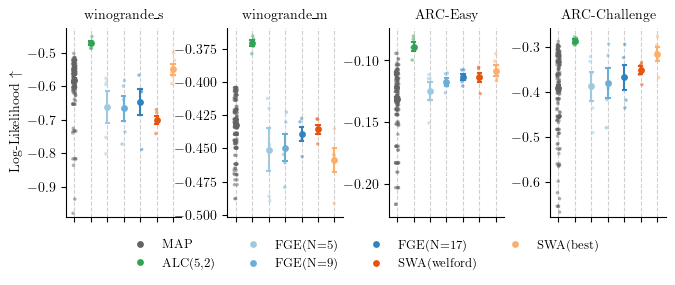

In [8]:
df_plot_ll = df_plot[df_plot["Metric"] == "ll"].copy()

full_ds_order = ["winogrande_s", "winogrande_m", "ARC-Easy", "ARC-Challenge", "obqa", "boolq"]
col_order_ds = [d for d in full_ds_order if d in df_plot_ll["Dataset"].unique()]

g = sns.catplot(
    data=df_plot_ll, y="value", x="Model",
    col="Dataset", col_wrap=min(4, len(col_order_ds)),
    col_order=col_order_ds,
    order=hue_order,
    kind="point", join=False, capsize=.2, linewidth=1.5,
    markers="o", palette=hue_palette, hue="Model",
    dodge=False, sharey=False, sharex=False, height=figsize[1]/1.4, aspect=1/1.4,
    legend=True, errorbar="se", hue_order=hue_order,
)

for ds, ax in g.axes_dict.items():
    subset = df_plot_ll[df_plot_ll["Dataset"] == ds]
    sns.stripplot(
        data=subset, y="value", x="Model",
        order=hue_order,
        ax=ax, palette=hue_palette, alpha=0.5, size=2.5,
        hue="Model", legend=False, hue_order=hue_order,
    )
    ax.grid(True, axis="x", linestyle="--", alpha=0.6)
    ax.set_ylabel("")
    ax.set_xticklabels([])

    def only_finite(x):
        return x[np.isfinite(x)]

    non_nan_vals = only_finite(subset["value"])
    if not non_nan_vals.empty:
        ax.set_ylim(bottom=non_nan_vals.min() - 0.01)

g.axes[0].set_ylabel(r"Log-Likelihood $\uparrow$")
g.set_titles(col_template="{col_name}")
g.set_xlabels("")
g.tight_layout()
g.fig.subplots_adjust(wspace=0.4)

sns.move_legend(g, loc="lower center", bbox_to_anchor=(0.45, -0.18), ncol=4, title="")

os.makedirs("result", exist_ok=True)
plt.savefig("result/performance_FGE_vs_SWA.pdf", dpi=300, bbox_inches="tight")
plt.show()

### Summary tables: mean LL per dataset (± 2·std over 5 seeds)

Full breakdown (FGE by ensemble size `N` snapshots) and a collapsed version pooling FGE over all 3
snapshot counts (15 runs/dataset) for a clean FGE-vs-SWA head-to-head.

In [9]:
def _fmt_stat(g):
    stat = pd.concat([g.mean().rename("mean"), g.std().rename("std")], axis=1)

    def fmt(row):
        if pd.isna(row["mean"]):
            return np.nan
        if pd.isna(row["std"]):
            return f"{row['mean']:.3f}"
        return f"{row['mean']:.3f} \u00b1 {2 * row['std']:.3f}"

    return stat.apply(fmt, axis=1)


ll_table_full = pd.DataFrame({
    "MAP": _fmt_stat(df_baseline[df_baseline["Model"] == "MAP"].groupby("Dataset")["ll"]),
    "ALC(5,2)": _fmt_stat(df_baseline[df_baseline["Model"] == "ALC(5,2)"].groupby("Dataset")["ll"]),
    "FGE_N5": _fmt_stat(df_fge[df_fge["NumSnapshots"] == 5].groupby("Dataset")["ll"]),
    "FGE_N9": _fmt_stat(df_fge[df_fge["NumSnapshots"] == 9].groupby("Dataset")["ll"]),
    "FGE_N17": _fmt_stat(df_fge[df_fge["NumSnapshots"] == 17].groupby("Dataset")["ll"]),
    "SWA_welford": _fmt_stat(df_swa[df_swa["Model"] == "SWA(welford)"].groupby("Dataset")["ll"]),
    "SWA_best": _fmt_stat(df_swa[df_swa["Model"] == "SWA(best)"].groupby("Dataset")["ll"]),
}).reset_index()
ll_table_full = ll_table_full.sort_values("Dataset").reset_index(drop=True)
ll_table_full

,Dataset,MAP,"ALC(5,2)",FGE_N5,FGE_N9,FGE_N17,SWA_welford,SWA_best
0,ARC-Challenge,-0.391 ± 0.171,-0.286 ± 0.017,-0.387 ± 0.146,-0.380 ± 0.151,-0.367 ± 0.120,-0.352 ± 0.041,-0.315 ± 0.069
1,ARC-Easy,-0.131 ± 0.049,-0.089 ± 0.015,-0.125 ± 0.033,-0.117 ± 0.014,-0.113 ± 0.012,-0.114 ± 0.017,-0.108 ± 0.020
2,winogrande_m,-0.432 ± 0.038,-0.371 ± 0.010,-0.451 ± 0.072,-0.450 ± 0.046,-0.439 ± 0.023,-0.436 ± 0.016,-0.459 ± 0.041
3,winogrande_s,-0.581 ± 0.143,-0.471 ± 0.030,-0.662 ± 0.213,-0.666 ± 0.168,-0.646 ± 0.169,-0.701 ± 0.057,-0.549 ± 0.075


In [10]:
ll_table = pd.DataFrame({
    "MAP": _fmt_stat(df_baseline[df_baseline["Model"] == "MAP"].groupby("Dataset")["ll"]),
    "ALC(5,2)": _fmt_stat(df_baseline[df_baseline["Model"] == "ALC(5,2)"].groupby("Dataset")["ll"]),
    "FGE": _fmt_stat(df_fge.groupby("Dataset")["ll"]),
    "SWA_welford": _fmt_stat(df_swa[df_swa["Model"] == "SWA(welford)"].groupby("Dataset")["ll"]),
    "SWA_best": _fmt_stat(df_swa[df_swa["Model"] == "SWA(best)"].groupby("Dataset")["ll"]),
}).reset_index()
ll_table = ll_table.sort_values("Dataset").reset_index(drop=True)
ll_table

,Dataset,MAP,"ALC(5,2)",FGE,SWA_welford,SWA_best
0,ARC-Challenge,-0.391 ± 0.171,-0.286 ± 0.017,-0.378 ± 0.131,-0.352 ± 0.041,-0.315 ± 0.069
1,ARC-Easy,-0.131 ± 0.049,-0.089 ± 0.015,-0.119 ± 0.022,-0.114 ± 0.017,-0.108 ± 0.020
2,winogrande_m,-0.432 ± 0.038,-0.371 ± 0.010,-0.447 ± 0.049,-0.436 ± 0.016,-0.459 ± 0.041
3,winogrande_s,-0.581 ± 0.143,-0.471 ± 0.030,-0.658 ± 0.172,-0.701 ± 0.057,-0.549 ± 0.075


In [11]:
# make markdown table for latex
print(ll_table_full.to_markdown())
print()
print(ll_table.to_markdown())

|    | Dataset       | MAP            | ALC(5,2)       | FGE_N5         | FGE_N9         | FGE_N17        | SWA_welford    | SWA_best       |
|---:|:--------------|:---------------|:---------------|:---------------|:---------------|:---------------|:---------------|:---------------|
|  0 | ARC-Challenge | -0.391 ± 0.171 | -0.286 ± 0.017 | -0.387 ± 0.146 | -0.380 ± 0.151 | -0.367 ± 0.120 | -0.352 ± 0.041 | -0.315 ± 0.069 |
|  1 | ARC-Easy      | -0.131 ± 0.049 | -0.089 ± 0.015 | -0.125 ± 0.033 | -0.117 ± 0.014 | -0.113 ± 0.012 | -0.114 ± 0.017 | -0.108 ± 0.020 |
|  2 | winogrande_m  | -0.432 ± 0.038 | -0.371 ± 0.010 | -0.451 ± 0.072 | -0.450 ± 0.046 | -0.439 ± 0.023 | -0.436 ± 0.016 | -0.459 ± 0.041 |
|  3 | winogrande_s  | -0.581 ± 0.143 | -0.471 ± 0.030 | -0.662 ± 0.213 | -0.666 ± 0.168 | -0.646 ± 0.169 | -0.701 ± 0.057 | -0.549 ± 0.075 |

|    | Dataset       | MAP            | ALC(5,2)       | FGE            | SWA_welford    | SWA_best       |
|---:|:--------------|:---------------|

### Which dataset shows the strongest SWA vs FGE gap?

Mean `(SWA_welford - FGE)` and `(SWA_best - FGE)` log-likelihood per dataset, on the raw numeric
means (FGE pooled over all 3 `cycle_steps`, matching the collapsed `ll_table` above).

In [12]:
fge_mean = df_fge.groupby("Dataset")["ll"].mean()
swa_welford_mean = df_swa[df_swa["Model"] == "SWA(welford)"].groupby("Dataset")["ll"].mean()
swa_best_mean = df_swa[df_swa["Model"] == "SWA(best)"].groupby("Dataset")["ll"].mean()

diff_df = pd.DataFrame({
    "FGE": fge_mean,
    "SWA_welford": swa_welford_mean,
    "SWA_best": swa_best_mean,
}).assign(
    gap_welford_minus_fge=lambda d: d["SWA_welford"] - d["FGE"],
    gap_best_minus_fge=lambda d: d["SWA_best"] - d["FGE"],
)
diff_df.sort_values("gap_best_minus_fge", key=np.abs, ascending=False)

,FGE,SWA_welford,SWA_best,gap_welford_minus_fge,gap_best_minus_fge
Dataset,,,,,
winogrande_s,-0.658046,-0.700722,-0.548571,-0.042676,0.109475
ARC-Challenge,-0.378251,-0.351597,-0.315001,0.026654,0.063250
winogrande_m,-0.446573,-0.435598,-0.458934,0.010975,-0.012360
ARC-Easy,-0.118512,-0.113764,-0.108232,0.004748,0.010281


In [13]:
selected_dataset = diff_df["gap_best_minus_fge"].abs().idxmax()
print(
    f"Strongest SWA_best vs FGE mean LL gap: {selected_dataset} "
    f"({diff_df.loc[selected_dataset, 'gap_best_minus_fge']:+.3f})"
)
selected_dataset

Strongest SWA_best vs FGE mean LL gap: winogrande_s (+0.109)


'winogrande_s'

In [14]:
ll_table_full[ll_table_full["Dataset"] == selected_dataset].to_markdown()

'|    | Dataset      | MAP            | ALC(5,2)       | FGE_N5         | FGE_N9         | FGE_N17        | SWA_welford    | SWA_best       |\n|---:|:-------------|:---------------|:---------------|:---------------|:---------------|:---------------|:---------------|:---------------|\n|  3 | winogrande_s | -0.581 ± 0.143 | -0.471 ± 0.030 | -0.662 ± 0.213 | -0.666 ± 0.168 | -0.646 ± 0.169 | -0.701 ± 0.057 | -0.549 ± 0.075 |'